# Ejercicio 12. Gale-Shapley con listas incompletas

Este cuaderno acompaña al informe [`ejercicio-12.md`](ejercicio-12.md). Ejecuta el
mismo código, comprueba la estabilidad con un oráculo que mira todos los pares,
vigila el potencial en cada propuesta, enumera todos los emparejamientos válidos en
instancias pequeñas y genera `ejercicio-12.png`. Las secciones siguen la numeración
del informe.

Para reproducirlo hacen falta Python 3, `matplotlib` e `IPython`.

In [1]:
from collections import deque
from itertools import product
from random import Random

import matplotlib.pyplot as plt
from IPython.display import Image, display

## 1. Formulación

Hay $n$ proponentes y $n$ receptores. El proponente `a` tiene una lista `lists[a]`
de receptores distintos, de mejor a peor, que puede ser vacía o tener cualquier
largo hasta $n$. Cada receptor tiene una lista completa y estricta de proponentes
en `pref_b[b]`. Un emparejamiento `M` es una lista donde `M[a]` es el receptor de
`a`, o `None`. El oráculo `blocking_pairs` aplica la definición del informe: quedar
solo es peor que cualquier receptor de la lista, y para el receptor, peor que
cualquier proponente.

In [2]:
def is_valid(M, lists):
    """M[a] es None o un receptor de lists[a], y no hay receptores repetidos."""
    used = [b for b in M if b is not None]
    return (len(M) == len(lists) and len(used) == len(set(used))
            and all(b is None or b in lists[a] for a, b in enumerate(M)))


def blocking_pairs(M, lists, pref_b):
    partner = {b: a for a, b in enumerate(M) if b is not None}
    pairs = []
    for a in range(len(lists)):
        for b in lists[a]:
            if b == M[a]:
                continue
            a_prefers = M[a] is None or lists[a].index(b) < lists[a].index(M[a])
            b_prefers = b not in partner or pref_b[b].index(a) < pref_b[b].index(partner[b])
            if a_prefers and b_prefers:
                pairs.append((a, b))
    return pairs


def all_valid_matchings(lists):
    n = len(lists)
    for M in product(*[[None] + lists[a] for a in range(n)]):
        if is_valid(list(M), lists):
            yield list(M)

Pruebas del oráculo: con listas incompletas, el emparejamiento vacío es inestable
si alguna pareja listada puede formarse, porque los dos prefieren estar juntos a
estar solos; y una pareja que no está en la lista de `a` no puede bloquear. En `[0, 1, None]`, `a0` prefiere `b1` a su pareja `b0` y `b1` prefiere a `a0`: bloquean.

In [3]:
lists = [[1, 0], [1], [0]]
pref_b = [[0, 1, 2], [2, 0, 1], [0, 1, 2]]
assert blocking_pairs([None, None, None], lists, pref_b) == [(0, 1), (0, 0), (1, 1), (2, 0)]
assert blocking_pairs([1, None, 0], lists, pref_b) == []
assert blocking_pairs([0, 1, None], lists, pref_b) == [(0, 1)]
assert not is_valid([2, None, None], lists)   # el receptor 2 no está en la lista de a0
assert not is_valid([1, 1, None], lists)      # receptor repetido
print("ok: definición de pareja bloqueante comprobada en casos explícitos")

ok: definición de pareja bloqueante comprobada en casos explícitos


## 2. El algoritmo

Solo entran en la cola los proponentes con algo pendiente en su lista. Un proponente
rechazado cuya lista se agotó se queda solo y no vuelve. Con `trace` se guarda, tras
cada propuesta, el potencial $\Phi=\sum_a(|L_a|-\texttt{next}[a])$ calculado desde
cero. La lista de preferencias de cada receptor se invierte en `rank`.

In [4]:
def gale_shapley_incomplete(lists, pref_b, order="cola", seed=0, trace=None):
    n = len(lists)
    if any(len(L) != len(set(L)) or any(not 0 <= b < n for b in L) for L in lists):
        raise ValueError("cada lista debe tener receptores distintos y válidos")
    rank = [[0] * n for _ in range(n)]       # rank[b][a]: lugar de a en la lista de b
    for b in range(n):
        for place, a in enumerate(pref_b[b]):
            rank[b][a] = place
    nxt = [0] * n                            # a qué lugar de su lista va a proponer a
    partner_of_b = [None] * n
    free = deque(a for a in range(n) if lists[a])
    rng = Random(seed)
    proposals = 0
    while free:
        if order == "azar":
            free.rotate(rng.randrange(len(free)))
        a = free.popleft() if order == "cola" else free.pop()
        b = lists[a][nxt[a]]
        nxt[a] += 1
        proposals += 1
        current = partner_of_b[b]
        if current is None:
            partner_of_b[b], loser = a, None
        elif rank[b][a] < rank[b][current]:
            partner_of_b[b], loser = a, current
        else:
            loser = a
        if loser is not None and nxt[loser] < len(lists[loser]):
            free.append(loser)               # si su lista se agotó, queda solo
        if trace is not None:
            phi = sum(len(L) - p for L, p in zip(lists, nxt))
            trace.append((a, b, current, partner_of_b[b], phi))
    M = [None] * n
    for b, a in enumerate(partner_of_b):
        if a is not None:
            M[a] = b
    return M, proposals

**Ejemplo.** Cuatro proponentes con listas incompletas. Dos quedan solos y dos
receptores nadie los lista. La traza se imprime con la estrategia de cola.

In [5]:
lists = [[1, 0], [1], [1, 2], [0]]
pref_b = [[3, 0, 1, 2], [2, 0, 1, 3], [0, 1, 2, 3], [0, 1, 2, 3]]
trace = []
M, proposals = gale_shapley_incomplete(lists, pref_b, trace=trace)
print("paso proponente receptor tenía queda con  phi")
phi0 = sum(len(L) for L in lists)
print(f"{0:>4} {'':>10} {'':>8} {'':>5} {'':>9} {phi0:>4}")
for step, (a, b, before, after, phi) in enumerate(trace, 1):
    name = lambda x: "—" if x is None else f"a{x}"
    print(f"{step:>4} {'a' + str(a):>10} {'b' + str(b):>8} {name(before):>5} {name(after):>9} {phi:>4}")
print("resultado:", [None if b is None else f"b{b}" for b in M], "en", proposals, "propuestas")
assert M == [None, None, 1, 0] and proposals == 5 and phi0 == 6
assert [t[4] for t in trace] == [5, 4, 3, 2, 1]
assert blocking_pairs(M, lists, pref_b) == []
assert M.count(None) == 2

paso proponente receptor tenía queda con  phi
   0                                        6
   1         a0       b1     —        a0    5
   2         a1       b1    a0        a0    4
   3         a2       b1    a0        a2    3
   4         a3       b0     —        a3    2
   5         a0       b0    a3        a3    1
resultado: [None, None, 'b1', 'b0'] en 5 propuestas


## 3. Potencial, validez y estabilidad en instancias aleatorias

Para 600 instancias con $1\le n\le12$, listas de largo aleatorio (incluida la vacía)
en orden aleatorio, y las cuatro ejecuciones (cola, pila y dos semillas al azar):
el resultado es válido, no tiene parejas bloqueantes, el número de propuestas no
supera $\sum_a|L_a|$ y el potencial baja exactamente 1 en cada propuesta.

In [6]:
def random_instance(n, rng, max_len=None):
    max_len = n if max_len is None else max_len
    lists = [rng.sample(range(n), rng.randint(0, max_len)) for _ in range(n)]
    pref_b = [rng.sample(range(n), n) for _ in range(n)]
    return lists, pref_b


RUNS = [("cola", 0), ("pila", 0), ("azar", 1), ("azar", 2)]
rng = Random(12)
instances = executions = single_total = proposer_total = 0
for _ in range(600):
    n = rng.randint(1, 12)
    lists, pref_b = random_instance(n, rng)
    bound = sum(len(L) for L in lists)
    for order, seed in RUNS:
        trace = []
        M, proposals = gale_shapley_incomplete(lists, pref_b, order, seed, trace)
        assert is_valid(M, lists)
        assert blocking_pairs(M, lists, pref_b) == []
        assert proposals == len(trace) <= bound
        phis = [bound] + [t[4] for t in trace]
        assert all(x - y == 1 for x, y in zip(phis, phis[1:])) and phis[-1] >= 0
        executions += 1
    instances += 1
    single_total += M.count(None)
    proposer_total += n
print(f"ok: {instances} instancias, {executions} ejecuciones; "
      f"{100 * single_total / proposer_total:.1f}% de los proponentes queda solo")

ok: 600 instancias, 2400 ejecuciones; 20.2% de los proponentes queda solo


## 4. Existencia y no perfección

En instancias pequeñas se enumeran todos los emparejamientos válidos. Se comprueba
que existe al menos uno estable, que el algoritmo devuelve uno de ellos, y se cuentan
las instancias donde el resultado deja a alguien solo. Con listas completas el
resultado tiene que ser perfecto; con las listas $[0],[0]$ es imposible.

In [7]:
rng = Random(13)
checked = imperfect = 0
for _ in range(400):
    n = rng.randint(1, 5)
    lists, pref_b = random_instance(n, rng)
    stable = [m for m in all_valid_matchings(lists) if not blocking_pairs(m, lists, pref_b)]
    assert stable, "debe existir un emparejamiento estable"
    M, _ = gale_shapley_incomplete(lists, pref_b)
    assert M in stable
    imperfect += None in M
    checked += 1
print(f"ok: {checked} instancias enumeradas; el resultado es estable en todas; "
      f"{imperfect} dejan a algún proponente solo")

rng = Random(14)
for _ in range(100):
    n = rng.randint(1, 10)
    lists = [rng.sample(range(n), n) for _ in range(n)]
    pref_b = [rng.sample(range(n), n) for _ in range(n)]
    M, _ = gale_shapley_incomplete(lists, pref_b)
    assert None not in M and sorted(M) == list(range(n))
print("ok: con listas completas el resultado es perfecto, 100 instancias")

M, _ = gale_shapley_incomplete([[0], [0]], [[0, 1], [0, 1]])
assert M == [0, None]
for L in ([[0, 0], [1]], [[2], [0]]):
    try:
        gale_shapley_incomplete(L, [[0, 1], [0, 1]])
        raise AssertionError("debía fallar")
    except ValueError:
        pass
print("ok: listas [0] y [0] dejan a un proponente solo, M =", M)

ok: 400 instancias enumeradas; el resultado es estable en todas; 292 dejan a algún proponente solo
ok: con listas completas el resultado es perfecto, 100 instancias
ok: listas [0] y [0] dejan a un proponente solo, M = [0, None]


## 5. Costo y figura

Con $n=60$ y listas de largo $k$ para todos, $k\in\{3,6,12,24,48,60\}$, 30
instancias por valor de $k$. Se mide el número medio de propuestas, frente a la cota
$nk=\sum_a|L_a|$, y la fracción media de proponentes que quedan solos.

In [8]:
N, SAMPLES = 60, 30
ks = [3, 6, 12, 24, 48, 60]
mean_proposals, mean_single = [], []
rng = Random(15)
print(f"{'k':>3} {'propuestas medias':>18} {'cota n*k':>9} {'proponentes solos':>18}")
for k in ks:
    props = singles = 0
    for _ in range(SAMPLES):
        lists = [rng.sample(range(N), k) for _ in range(N)]
        pref_b = [rng.sample(range(N), N) for _ in range(N)]
        M, proposals = gale_shapley_incomplete(lists, pref_b)
        assert proposals <= N * k and blocking_pairs(M, lists, pref_b) == []
        props += proposals
        singles += M.count(None)
    mean_proposals.append(props / SAMPLES)
    mean_single.append(100 * singles / (SAMPLES * N))
    print(f"{k:>3} {mean_proposals[-1]:>18.1f} {N * k:>9} {mean_single[-1]:>17.1f}%")

  k  propuestas medias  cota n*k  proponentes solos
  3              109.1       180              14.4%
  6              153.7       360               5.9%
 12              207.9       720               1.8%


 24              263.2      1440               0.2%


 48              257.8      2880               0.0%
 60              282.1      3600               0.0%


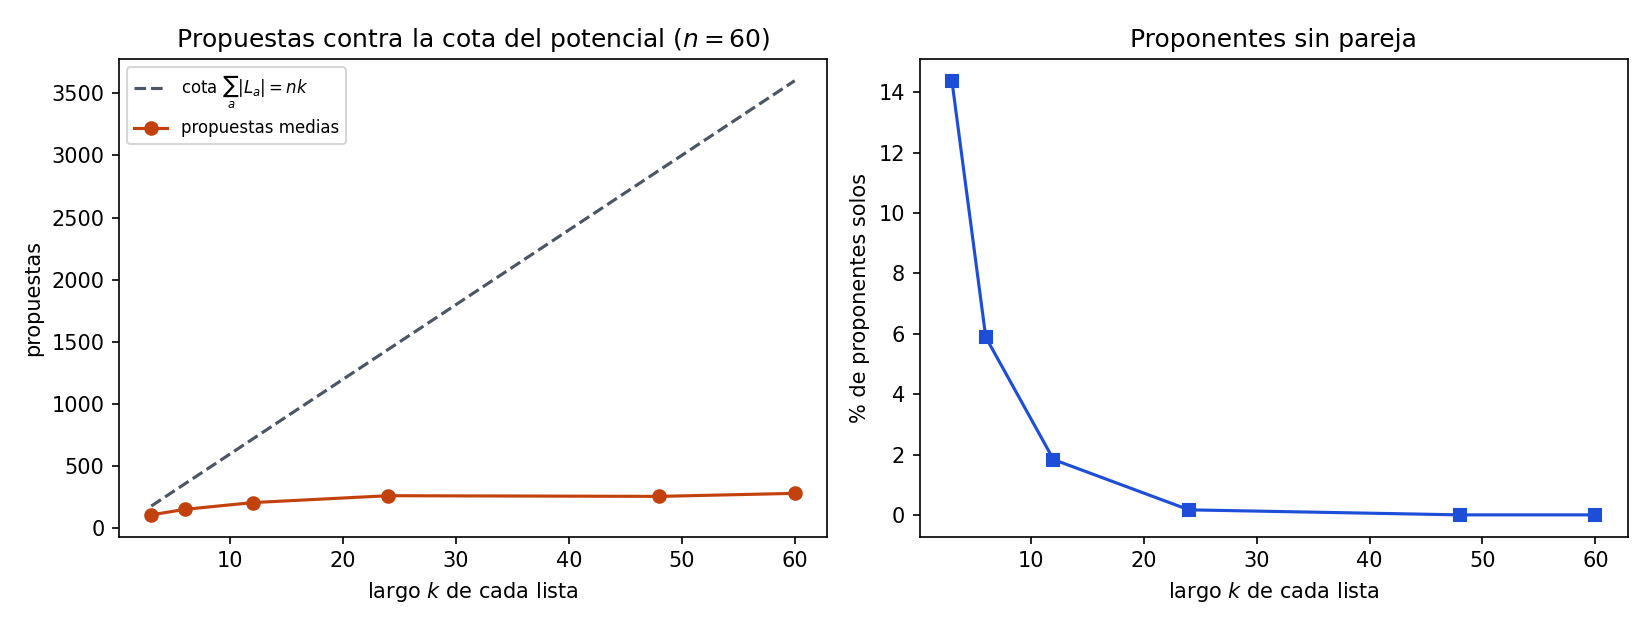

In [9]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2))
left.plot(ks, [N * k for k in ks], "--", color="#4b5563", label="cota $\\sum_a |L_a| = nk$")
left.plot(ks, mean_proposals, "o-", color="#c2410c", label="propuestas medias")
left.set_xlabel("largo $k$ de cada lista")
left.set_ylabel("propuestas")
left.set_title("Propuestas contra la cota del potencial ($n=60$)")
left.legend(fontsize=8)
right.plot(ks, mean_single, "s-", color="#1d4ed8")
right.set_xlabel("largo $k$ de cada lista")
right.set_ylabel("% de proponentes solos")
right.set_title("Proponentes sin pareja")
fig.tight_layout()
fig.savefig("ejercicio-12.png", dpi=150)
plt.close(fig)
display(Image("ejercicio-12.png"))